# PathSnap — Logistic Regression: Clean Data, Better Features, Bayesian Tuning
Logistic-only notebook. Pipeline: load raw trips → **validate & clean** → build candidate features (point-to-segment distance in metres, neighbour support, smoothed heading, speed) → baseline vs improved Logistic Regression → **Bayesian (Optuna/TPE) tuning** → final evaluation on the 10 student-test trips → save artifacts for the API.

**What changed vs the previous notebook**
1. The old "test" set was 16 trips carved out of train. Here: **train = 80 train trips, development test = the 10 `student_test` trips**, as the guidelines require.
2. Candidates are ranked by true **point-to-segment distance in metres** (old version used distance to the arc midpoint).
3. New label-free features: neighbour support, distance rank/gap, smoothed heading, speed, position along the arc.
4. Tuning objective is **observation-level Top-1 accuracy** with **group (trip) CV**, not row-level macro F1.
5. Feature code lives in one file (`pathsnap_features.py`) that the API reuses, so training and inference build identical features.

## 1. Setup & Imports

In [4]:
!pip -q install optuna
import os, zipfile, time, json, joblib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, log_loss, confusion_matrix, classification_report)

optuna.logging.set_verbosity(optuna.logging.WARNING)
SEED = 42

## 2. Load Raw Dataset

In [5]:
ZIP_PATH = "/content/Student folder.zip"
EXTRACT_DIR = Path("/content/Student_Folder")

with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    z.extractall(EXTRACT_DIR)

BASE_DIR = EXTRACT_DIR / "Student folder"
train_dir = BASE_DIR / "train"
test_dir = BASE_DIR / "student_test"
PARTITIONS = {"train": train_dir, "student_test": test_dir}

print("Extracted to:", EXTRACT_DIR)
print("train exists:", train_dir.exists(), "| student_test exists:", test_dir.exists())

Extracted to: /content/Student_Folder
train exists: True | student_test exists: True


### 2.1 Shared feature module
This cell writes `pathsnap_features.py` (loaders, cleaning, candidate generation, features, observation-level metrics). **Copy this same file into your API folder** and import it from `pipeline.py`.

In [6]:
%%writefile pathsnap_features.py
"""PathSnap shared data + feature code.

Used by the training notebook AND by the API (api/pipeline.py) so that training
and inference build features in exactly the same way.
Ground truth (.route) is only used when `route` is passed in (training / scoring).
"""
import os
import numpy as np
import pandas as pd
from pathlib import Path
from scipy.spatial import cKDTree

R_EARTH = 6371000.0

# ---- candidate generation / feature config (saved with the model) ----
K_FINAL = 10        # candidates kept per GPS point
K_PRE = 40          # arcs pre-selected by midpoint distance, then re-ranked by exact point-to-segment distance
HEAD_WIN = 2        # heading/speed measured from point i-2 to i+2
NBR_OFFSETS = (-2, -1, 1, 2)   # neighbouring points used for the "neighbour support" feature

FEATURES = [
    "dist_m", "dist_rank", "dist_gap_m", "nbr_dist_m",
    "heading_diff_deg", "cos_heading", "cos_heading_w",
    "speed_mps", "along_frac", "arc_len_m",
]


# ---------------------------------------------------------------- loaders
def get_trip_ids(partition_dir):
    return sorted(os.listdir(partition_dir))


def find_file(trip_dir, ext):
    matches = [f for f in os.listdir(trip_dir) if f.endswith(ext)]
    return Path(trip_dir) / matches[0] if matches else None


def load_track(path):
    return pd.read_csv(path, sep=r"\s+", header=None, names=["lon", "lat", "timestamp"])


def load_nodes(path):
    df = pd.read_csv(path, sep=r"\s+", header=None, names=["lon", "lat"])
    df.index.name = "node_id"
    return df


def load_arcs(path):
    df = pd.read_csv(path, sep=r"\s+", header=None, names=["from_node_id", "to_node_id"])
    df.index.name = "arc_id"
    return df


def load_route(path):
    return pd.read_csv(path, sep=r"\s+", header=None, names=["arc_id"])


def load_trip(partition_dir, trip_id, with_route=True):
    trip_dir = Path(partition_dir) / trip_id
    spec = [("track", ".track", load_track), ("nodes", ".nodes", load_nodes),
            ("arcs", ".arcs", load_arcs)]
    if with_route:
        spec.append(("route", ".route", load_route))
    data = {}
    for key, ext, loader in spec:
        p = find_file(trip_dir, ext)
        data[key] = loader(p) if p is not None else None
    return data


# ---------------------------------------------------------------- cleaning
def clean_track(track):
    """Drop NaN / impossible coordinates, sort by time, drop duplicate timestamps.
    Keeps `orig_idx` (row number in the raw file) so predictions can be mapped back."""
    t = track.copy()
    t["orig_idx"] = np.arange(len(t))
    n0 = len(t)
    t = t.dropna()
    t = t[t["lat"].between(-90, 90) & t["lon"].between(-180, 180)]
    t = t.sort_values("timestamp", kind="stable")
    t = t.drop_duplicates(subset="timestamp", keep="first").reset_index(drop=True)
    return t, n0 - len(t)


# ---------------------------------------------------------------- geometry
def _project(lon, lat, lon0, lat0):
    """Local equirectangular projection to metres (accurate at city scale)."""
    x = R_EARTH * np.radians(np.asarray(lon) - lon0) * np.cos(np.radians(lat0))
    y = R_EARTH * np.radians(np.asarray(lat) - lat0)
    return x, y


def _seg_dist(P, A, B):
    """Distance from points P to segments AB (broadcasting). Returns (dist, t in [0,1])."""
    AB = B - A
    denom = np.maximum((AB ** 2).sum(-1), 1e-9)
    t = np.clip(((P - A) * AB).sum(-1) / denom, 0.0, 1.0)
    proj = A + t[..., None] * AB
    return np.sqrt(((P - proj) ** 2).sum(-1)), t


def _bearing(dx, dy):
    return (np.degrees(np.arctan2(dx, dy)) + 360.0) % 360.0


def _hdiff(b1, b2):
    d = np.abs(b1 - b2) % 360.0
    return np.minimum(d, 360.0 - d)


# ---------------------------------------------------------------- features
def build_trip_features(track, nodes, arcs, route=None, trip_id="trip"):
    """Candidate table for one trip: K_FINAL candidate arcs per GPS point.
    If `route` is given a `label` column is added (1 = candidate arc is in the reference route)."""
    track, _ = clean_track(track)
    n = len(track)
    if n == 0:
        return None

    lon0, lat0 = track["lon"].mean(), track["lat"].mean()
    px, py = _project(track["lon"].values, track["lat"].values, lon0, lat0)
    P = np.column_stack([px, py])
    ts = track["timestamp"].values.astype(float)

    nx, ny = _project(nodes["lon"].values, nodes["lat"].values, lon0, lat0)
    N = np.column_stack([nx, ny])
    A = N[arcs["from_node_id"].values]
    B = N[arcs["to_node_id"].values]
    arc_len = np.sqrt(((B - A) ** 2).sum(1))
    arc_brg = _bearing(B[:, 0] - A[:, 0], B[:, 1] - A[:, 1])

    # 1) pre-select by midpoint distance, 2) re-rank by exact point-to-segment distance
    n_arcs = len(arcs)
    kpre = min(K_PRE, n_arcs)
    kfin = min(K_FINAL, kpre)
    tree = cKDTree((A + B) / 2.0)
    _, pre = tree.query(P, k=kpre)
    pre = pre.reshape(n, kpre)
    d_pre, t_pre = _seg_dist(P[:, None, :], A[pre], B[pre])
    order = np.argsort(d_pre, axis=1)[:, :kfin]
    cand = np.take_along_axis(pre, order, axis=1)          # (n, kfin) arc ids
    dist = np.take_along_axis(d_pre, order, axis=1)
    along = np.take_along_axis(t_pre, order, axis=1)

    # neighbour support: distance of neighbouring GPS points to the same candidate arc
    idx = np.arange(n)
    nb = []
    for o in NBR_OFFSETS:
        j = np.clip(idx + o, 0, n - 1)
        dj, _ = _seg_dist(P[j][:, None, :], A[cand], B[cand])
        nb.append(dj)
    nbr = np.mean(nb, axis=0)

    # smoothed heading + speed of the vehicle
    lo, hi = np.clip(idx - HEAD_WIN, 0, n - 1), np.clip(idx + HEAD_WIN, 0, n - 1)
    dxy = P[hi] - P[lo]
    dt = np.maximum(ts[hi] - ts[lo], 1e-6)
    speed = np.sqrt((dxy ** 2).sum(1)) / dt
    gps_brg = _bearing(dxy[:, 0], dxy[:, 1])
    hd = _hdiff(gps_brg[:, None], arc_brg[cand])
    cosh = np.cos(np.radians(hd))
    conf = np.clip(speed / 5.0, 0, 1)[:, None]

    out = {
        "trip_id": np.repeat(trip_id, n * kfin),
        "point_idx": np.repeat(idx, kfin),
        "orig_idx": np.repeat(track["orig_idx"].values, kfin),
        "candidate_arc_id": cand.ravel(),
        "dist_m": dist.ravel(),
        "dist_rank": np.tile(np.arange(kfin), n),
        "dist_gap_m": (dist - dist[:, [0]]).ravel(),
        "nbr_dist_m": nbr.ravel(),
        "heading_diff_deg": hd.ravel(),
        "cos_heading": cosh.ravel(),
        "cos_heading_w": (cosh * conf).ravel(),
        "speed_mps": np.repeat(speed, kfin),
        "along_frac": along.ravel(),
        "arc_len_m": arc_len[cand].ravel(),
    }
    df = pd.DataFrame(out)
    if route is not None:
        gt = set(route["arc_id"].astype(int).tolist())
        df["label"] = np.isin(df["candidate_arc_id"].values, list(gt)).astype(np.int8)
    return df


def build_feature_dataset(partition_dir, trip_ids, with_route=True):
    tables = []
    for tid in trip_ids:
        d = load_trip(partition_dir, tid, with_route=with_route)
        if any(d[k] is None for k in d):
            print("skipping (missing file):", tid)
            continue
        t = build_trip_features(d["track"], d["nodes"], d["arcs"],
                                d.get("route"), trip_id=tid)
        if t is not None:
            tables.append(t)
    return pd.concat(tables, ignore_index=True)


# ---------------------------------------------------------------- metrics
def observation_metrics(trip_id, point_idx, prob, label):
    """Observation-level metrics. For each GPS point take the highest-scored candidate.
    top1_all  : correct / all points (points whose reference arc is missing count as wrong)
    top1_cond : correct / points where the reference arc is in the candidate set
    miss_rate : share of points with NO reference arc among the candidates"""
    key = pd.factorize(pd.Series(trip_id).astype(str) + "_" + pd.Series(point_idx).astype(str))[0]
    prob, label = np.asarray(prob), np.asarray(label)
    order = np.lexsort((-prob, key))
    ks = key[order]
    first = np.r_[True, ks[1:] != ks[:-1]]
    top = order[first]
    n_pts = len(top)
    has_pos = np.bincount(key, weights=label) > 0
    correct = label[top].sum()
    return {
        "top1_all": correct / n_pts,
        "top1_cond": correct / max(has_pos.sum(), 1),
        "miss_rate": 1 - has_pos.mean(),
        "n_points": n_pts,
    }

Overwriting pathsnap_features.py


In [7]:
import importlib
import pathsnap_features as pf
importlib.reload(pf)
FEATURES = pf.FEATURES
print("Features:", FEATURES)

Features: ['dist_m', 'dist_rank', 'dist_gap_m', 'nbr_dist_m', 'heading_diff_deg', 'cos_heading', 'cos_heading_w', 'speed_mps', 'along_frac', 'arc_len_m']


## 3. Data Validation & Cleaning
Every trip is checked before it is used. Rules:
- **Train trips** that fail a hard check (missing file, invalid node/arc/route ids, GPS far outside the road network) are **excluded from training**.
- **Student-test trips are never dropped** — they are only reported — so test scores reflect the real pipeline.
- GPS jumps and disconnected reference routes are **flagged, not silently altered** (the reference route is treated as a reference, not perfect truth).

In [8]:
def validate_trip(partition_dir, trip_id):
    d = pf.load_trip(partition_dir, trip_id)
    row = {"trip": trip_id}
    missing = [k for k, v in d.items() if v is None]
    row["missing_files"] = ",".join(missing)
    if missing:
        row["usable"] = False
        return row

    track, nodes, arcs, route = d["track"], d["nodes"], d["arcs"], d["route"]
    clean, n_removed = pf.clean_track(track)

    row["n_points_raw"] = len(track)
    row["n_removed_by_cleaning"] = n_removed
    row["n_nodes"], row["n_arcs"] = len(nodes), len(arcs)

    dt = clean["timestamp"].diff().dropna()
    row["pct_dt_eq_1s"] = float((dt == 1).mean()) if len(dt) else np.nan
    row["max_gap_s"] = float(dt.max()) if len(dt) else np.nan

    # implied speed between consecutive points (flag GPS jumps)
    lat_m = np.radians(clean["lat"].diff().values) * pf.R_EARTH
    lon_m = np.radians(clean["lon"].diff().values) * pf.R_EARTH * np.cos(np.radians(clean["lat"].values))
    step = np.sqrt(lat_m**2 + lon_m**2)[1:]
    spd = step / np.maximum(dt.values, 1e-6)
    row["max_speed_mps"] = float(np.nanmax(spd)) if len(spd) else np.nan
    row["n_gps_jumps_gt70mps"] = int((spd > 70).sum())

    # network sanity
    row["arc_node_ids_valid"] = bool(arcs.min().min() >= 0 and arcs.max().max() < len(nodes))
    row["n_isolated_nodes"] = int(len(set(nodes.index) - set(arcs["from_node_id"]) - set(arcs["to_node_id"])))

    # reference route sanity
    r = route["arc_id"].values
    row["route_ids_valid"] = bool(len(r) > 0 and r.min() >= 0 and r.max() < len(arcs))
    row["n_route_arcs"] = int(len(r))
    if row["route_ids_valid"] and len(r) > 1:
        to_n = arcs["to_node_id"].values[r[:-1]]
        from_n = arcs["from_node_id"].values[r[1:]]
        row["pct_route_connected"] = float((to_n == from_n).mean())
    else:
        row["pct_route_connected"] = np.nan

    # GPS plausibility: points should be near the road network (catches lon/lat swaps)
    m = 0.005  # ~500 m margin in degrees
    inside = (clean["lon"].between(nodes["lon"].min() - m, nodes["lon"].max() + m) &
              clean["lat"].between(nodes["lat"].min() - m, nodes["lat"].max() + m))
    row["pct_points_in_network_bbox"] = float(inside.mean())

    row["usable"] = bool(row["arc_node_ids_valid"] and row["route_ids_valid"]
                         and row["pct_points_in_network_bbox"] > 0.95 and len(clean) >= 5)
    return row

quality = {}
for name, pdir in PARTITIONS.items():
    quality[name] = pd.DataFrame([validate_trip(pdir, t) for t in pf.get_trip_ids(pdir)]).set_index("trip")
    quality[name].to_csv(f"data_quality_{name}.csv")

for name, q in quality.items():
    print(f"=== {name}: {len(q)} trips | usable: {int(q['usable'].sum())} | "
          f"removed GPS rows: {int(q['n_removed_by_cleaning'].fillna(0).sum())} | "
          f"trips with GPS jumps >70 m/s: {int((q['n_gps_jumps_gt70mps'].fillna(0) > 0).sum())} | "
          f"mean route connectivity: {q['pct_route_connected'].mean():.3f}")
    display(q[~q["usable"]] if (~q["usable"]).any() else q.head(3))

=== train: 80 trips | usable: 80 | removed GPS rows: 0 | trips with GPS jumps >70 m/s: 10 | mean route connectivity: 0.999


,missing_files,n_points_raw,n_removed_by_cleaning,n_nodes,n_arcs,pct_dt_eq_1s,max_gap_s,max_speed_mps,n_gps_jumps_gt70mps,arc_node_ids_valid,n_isolated_nodes,route_ids_valid,n_route_arcs,pct_route_connected,pct_points_in_network_bbox,usable
trip,,,,,,,,,,,,,,,,
00000001,,1315,0,88809,165790,0.980974,16.0,72.421158,1,True,0,True,525,1.000000,1.0,True
00000002,,7243,0,7936,16139,0.974455,160.0,37.274320,0,True,0,True,262,0.996169,1.0,True
00000003,,821,0,9138,18028,0.996341,2.0,29.131617,0,True,0,True,79,1.000000,1.0,True


=== student_test: 10 trips | usable: 10 | removed GPS rows: 0 | trips with GPS jumps >70 m/s: 1 | mean route connectivity: 1.000


,missing_files,n_points_raw,n_removed_by_cleaning,n_nodes,n_arcs,pct_dt_eq_1s,max_gap_s,max_speed_mps,n_gps_jumps_gt70mps,arc_node_ids_valid,n_isolated_nodes,route_ids_valid,n_route_arcs,pct_route_connected,pct_points_in_network_bbox,usable
trip,,,,,,,,,,,,,,,,
00000000,,2503,0,8542,18196,0.999600,2.0,63.707072,0,True,0,True,179,1.0,1.0,True
00000007,,1354,0,2061,4369,1.000000,1.0,49.656031,0,True,0,True,123,1.0,1.0,True
00000009,,1049,0,6745,13106,0.999046,2.0,48.887227,0,True,0,True,429,1.0,1.0,True


In [9]:
usable_train = quality["train"].index[quality["train"]["usable"]].tolist()
excluded_train = quality["train"].index[~quality["train"]["usable"]].tolist()
test_ids = pf.get_trip_ids(test_dir)   # never dropped

print("Train trips used:", len(usable_train), "| excluded:", excluded_train)
print("Student-test trips:", len(test_ids))

Train trips used: 80 | excluded: []
Student-test trips: 10


## 4. Candidate Generation & Feature Engineering
For every (cleaned) GPS point: take the `K_FINAL` nearest road segments by exact point-to-segment distance (metres, local projection), then compute features. **Label** = candidate arc is in the trip's reference route. (The route file has no per-point timestamps, so this is the best available label; some "positives" can be a road the vehicle visits at another time — this limits the ceiling and is why the HMM step matters.)

| Feature | Meaning |
|---|---|
| `dist_m`, `dist_rank`, `dist_gap_m` | distance to candidate, its rank, and gap to the nearest candidate |
| `nbr_dist_m` | mean distance of the 4 neighbouring GPS points to the same candidate (path consistency) |
| `heading_diff_deg`, `cos_heading`, `cos_heading_w` | smoothed vehicle heading vs arc direction; last one down-weighted at low speed |
| `speed_mps` | smoothed speed (tells the model how much to trust heading) |
| `along_frac`, `arc_len_m` | position along the candidate arc, and arc length |

In [10]:
t0 = time.time()
train_raw = pf.build_feature_dataset(train_dir, usable_train)
test_df = pf.build_feature_dataset(test_dir, test_ids)
print("Built in", round(time.time() - t0), "s")
print("train rows:", len(train_raw), "| student_test rows:", len(test_df))

Built in 24 s
train rows: 2084170 | student_test rows: 191600


In [11]:
# ---- row-level cleaning (TRAIN ONLY) ----
bad = ~np.isfinite(train_raw[FEATURES].values).all(axis=1)
print("rows with NaN/inf features:", int(bad.sum()))
train_raw = train_raw[~bad]

# points where the reference arc is not among the candidates carry no positive example
key = pd.factorize(train_raw["trip_id"] + "_" + train_raw["point_idx"].astype(str))[0]
has_pos = np.bincount(key, weights=train_raw["label"].values) > 0
train_df = train_raw[has_pos[key]].reset_index(drop=True)
print("train points dropped (no positive candidate):", int((~has_pos).sum()), "of", len(has_pos))

# ---- candidate-set quality on ALL points (nothing dropped) ----
for name, d in [("train (before dropping)", train_raw), ("student_test", test_df)]:
    m = pf.observation_metrics(d["trip_id"].values, d["point_idx"].values, -d["dist_m"].values, d["label"].values)
    print(f"{name:26s} candidate miss rate = {m['miss_rate']:.4f} | nearest-road Top-1 = {m['top1_all']:.4f}")

print("\nlabel balance (train):", train_df["label"].value_counts(normalize=True).round(3).to_dict())
train_df.to_parquet("train_features.parquet", index=False)
test_df.to_parquet("test_features.parquet", index=False)
display(train_df.groupby("label")[FEATURES].mean().T)

rows with NaN/inf features: 0
train points dropped (no positive candidate): 15795 of 208417
train (before dropping)    candidate miss rate = 0.0758 | nearest-road Top-1 = 0.5298
student_test               candidate miss rate = 0.0025 | nearest-road Top-1 = 0.5996

label balance (train): {0: 0.642, 1: 0.358}


label,0,1
dist_m,79.161589,71.567718
dist_rank,4.847252,3.877676
dist_gap_m,68.451461,63.650852
nbr_dist_m,82.303905,73.857864
heading_diff_deg,116.461350,36.456129
cos_heading,-0.325983,0.661887
cos_heading_w,-0.301516,0.609517
speed_mps,11.649782,10.549042
along_frac,0.494464,0.508695
arc_len_m,104.799677,123.647610


## 5. Evaluation Helpers
- **CV** = 5-fold **GroupKFold by trip** on the training trips (no trip appears in both sides of a fold).
- All CV numbers (baseline, untuned, tuned) use the **same** point-subsample of the training data (`TUNE_FRAC`) and the same folds, so comparisons are fair and fast.
- **Student-test** metrics use all 10 test trips, all points, no filtering.

In [12]:
TUNE_FRAC = 0.05
BASE_FEATURES = ["dist_m", "heading_diff_deg"]   # the two features of the previous notebook

# point-level subsample (keeps all candidates of a chosen point)
pkey = pd.factorize(train_df["trip_id"] + "_" + train_df["point_idx"].astype(str))[0]
rng = np.random.RandomState(SEED)
chosen = rng.rand(pkey.max() + 1) < TUNE_FRAC
cv_df = train_df[chosen[pkey]].reset_index(drop=True)
folds = list(GroupKFold(n_splits=3).split(cv_df, groups=cv_df["trip_id"]))
print("CV subsample rows:", len(cv_df), "| trips:", cv_df["trip_id"].nunique())

def build_pipe(C=1.0, class_weight=None, degree=1):
    steps = []
    if degree > 1:
        steps.append(("poly", PolynomialFeatures(degree=degree, include_bias=False)))
    steps.append(("scale", StandardScaler()))
    steps.append(("lr", LogisticRegression(C=C, class_weight=class_weight, max_iter=300, tol=1e-3)))
    return Pipeline(steps)

def group_cv(make_model, feats):
    rows = []
    for tr, va in folds:
        m = make_model()
        m.fit(cv_df.iloc[tr][feats], cv_df.iloc[tr]["label"])
        v = cv_df.iloc[va]
        prob = m.predict_proba(v[feats])[:, 1]
        y = v["label"].values
        obs = pf.observation_metrics(v["trip_id"].values, v["point_idx"].values, prob, y)
        rows.append({"top1": obs["top1_all"],
                     "macro_f1": f1_score(y, (prob >= 0.5).astype(int), average="macro"),
                     "logloss": log_loss(y, prob)})
    r = pd.DataFrame(rows)
    return r.mean().to_dict(), r.std().to_dict()

def evaluate(model, df, feats):
    y = df["label"].values
    t0 = time.time()
    prob = model.predict_proba(df[feats])[:, 1]
    inf_t = time.time() - t0
    pred = (prob >= 0.5).astype(int)
    obs = pf.observation_metrics(df["trip_id"].values, df["point_idx"].values, prob, y)
    return {
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred),
        "Recall": recall_score(y, pred),
        "Macro F1": f1_score(y, pred, average="macro"),
        "Log Loss": log_loss(y, prob),
        "Top-1 (all points)": obs["top1_all"],
        "Top-1 (ref arc in candidates)": obs["top1_cond"],
        "Candidate Miss Rate": obs["miss_rate"],
        "Inference Time (s)": inf_t,
    }, prob

CV subsample rows: 287780 | trips: 80


## 6. Baseline vs Improved (untuned) Logistic Regression

In [13]:
specs = {
    "LR baseline (2 features, as before)": dict(feats=BASE_FEATURES,
        make=lambda: LogisticRegression(max_iter=1000), cfg="dist_m + heading_diff_deg, C=1, max_iter=1000"),
    "LR improved (untuned)": dict(feats=FEATURES,
        make=lambda: build_pipe(C=1.0, class_weight=None, degree=1), cfg="10 features, scaled, C=1, no poly"),
}

models, rows, probs = {}, [], {}
for name, s in specs.items():
    cvm, cvs = group_cv(s["make"], s["feats"])
    m = s["make"]()
    t0 = time.time(); m.fit(train_df[s["feats"]], train_df["label"]); fit_t = time.time() - t0
    te, p = evaluate(m, test_df, s["feats"])
    tr_, _ = evaluate(m, train_df, s["feats"])
    models[name] = (m, s["feats"]); probs[name] = p
    rows.append({"Model": name, "Config": s["cfg"],
                 "CV Top-1": cvm["top1"], "CV Top-1 std": cvs["top1"],
                 "CV Macro F1": cvm["macro_f1"], "CV Log Loss": cvm["logloss"],
                 "Train Top-1": tr_["Top-1 (all points)"], "Fit Time (s)": fit_t,
                 **{f"Test {k}": v for k, v in te.items()}})
results = pd.DataFrame(rows)
display(results.set_index("Model").T.round(4))

Model,"LR baseline (2 features, as before)",LR improved (untuned)
Config,"dist_m + heading_diff_deg, C=1, max_iter=1000","10 features, scaled, C=1, no poly"
CV Top-1,0.772219,0.838626
CV Top-1 std,0.097644,0.098061
CV Macro F1,0.787515,0.79851
CV Log Loss,0.469257,0.434753
Train Top-1,0.777076,0.843652
Fit Time (s),3.802881,11.366574
Test Accuracy,0.795506,0.803356
Test Precision,0.740397,0.766917
Test Recall,0.72777,0.708023


## 7. Bayesian Hyperparameter Optimisation (Optuna, TPE sampler)
- **Search space:** `C` (log 1e-3 → 100), `class_weight` (None / balanced), polynomial `degree` (1 / 2).
- **Objective:** maximise mean **observation-level Top-1 accuracy** over 5 trip-grouped CV folds on the training trips only.
- **Student-test trips are not used** for the search space, objective, or choice of parameters.
- Every trial is recorded and saved.

In [17]:
N_TRIALS = 15

def objective(trial):
    C = trial.suggest_float("C", 1e-3, 100, log=True)
    cw = trial.suggest_categorical("class_weight", [None, "balanced"])
    degree = trial.suggest_int("degree", 1, 2)
    cvm, cvs = group_cv(lambda: build_pipe(C, cw, degree), FEATURES)
    trial.set_user_attr("cv_macro_f1", cvm["macro_f1"])
    trial.set_user_attr("cv_logloss", cvm["logloss"])
    trial.set_user_attr("cv_top1_std", cvs["top1"])
    return cvm["top1"]

t0 = time.time()
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=N_TRIALS, timeout=900)
tune_time = time.time() - t0

print("Best CV Top-1:", round(study.best_value, 4))
print("Best params  :", study.best_params)
print("Trials:", len(study.trials), "| tuning time (s):", round(tune_time))

trials = study.trials_dataframe()
trials.to_csv("bayesian_trials_logreg.csv", index=False)
json.dump({"best_params": study.best_params, "best_cv_top1": study.best_value,
           "n_trials": N_TRIALS, "tuning_time_s": tune_time, "seed": SEED, "tune_frac": TUNE_FRAC},
          open("bayesian_best_logreg.json", "w"), indent=2)
display(trials.sort_values("value", ascending=False).head(10))

Best CV Top-1: 0.8415
Best params  : {'C': 0.0018393753185177353, 'class_weight': None, 'degree': 1}
Trials: 15 | tuning time (s): 530


,number,value,datetime_start,datetime_complete,duration,params_C,params_class_weight,params_degree,user_attrs_cv_logloss,user_attrs_cv_macro_f1,user_attrs_cv_top1_std,system_attrs_tpe:relative_params:0,state
11,11,0.841515,2026-11-18 10:01:14.560777,2026-11-18 10:01:22.195413,0 days 00:00:07.634636,0.001839,None,1,0.436391,0.797256,0.099441,"{""C"": 0.0018393753185177353, ""class_weight"": n...",COMPLETE
14,14,0.841411,2026-11-18 10:01:37.075808,2026-11-18 10:01:43.225398,0 days 00:00:06.149590,0.002446,balanced,1,0.460077,0.778689,0.099588,"{""C"": 0.0024460352196481075, ""class_weight"": ""...",COMPLETE
10,10,0.841410,2026-11-18 10:01:08.542835,2026-11-18 10:01:14.560703,0 days 00:00:06.017868,0.004632,None,1,0.434674,0.798332,0.099199,"{""C"": 0.004632104910082419, ""class_weight"": nu...",COMPLETE
12,12,0.841376,2026-11-18 10:01:22.195484,2026-11-18 10:01:27.938842,0 days 00:00:05.743358,0.002520,None,1,0.435699,0.797576,0.099612,"{""C"": 0.002519694945194793, ""class_weight"": nu...",COMPLETE
13,13,0.840850,2026-11-18 10:01:27.938910,2026-11-18 10:01:37.075723,0 days 00:00:09.136813,0.017231,None,1,0.434178,0.798790,0.098731,"{""C"": 0.017231093851279737, ""class_weight"": nu...",COMPLETE
4,4,0.839841,2026-11-18 09:58:05.044123,2026-11-18 09:58:15.708600,0 days 00:00:10.664477,0.033206,None,1,0.434147,0.799036,0.098331,NaN,COMPLETE
9,9,0.839772,2026-11-18 10:00:57.344569,2026-11-18 10:01:08.542765,0 days 00:00:11.198196,0.033348,balanced,1,0.459210,0.780447,0.098490,NaN,COMPLETE
7,7,0.838903,2026-11-18 10:00:16.180074,2026-11-18 10:00:27.928702,0 days 00:00:11.748628,0.916374,balanced,1,0.459909,0.780355,0.098349,NaN,COMPLETE
5,5,0.838834,2026-11-18 09:58:15.708690,2026-11-18 09:58:26.505165,0 days 00:00:10.796475,1.146211,balanced,1,0.460358,0.780027,0.098304,NaN,COMPLETE
3,3,0.838557,2026-11-18 09:57:49.952358,2026-11-18 09:58:05.043750,0 days 00:00:15.091392,14.528247,None,1,0.434832,0.798468,0.098027,NaN,COMPLETE


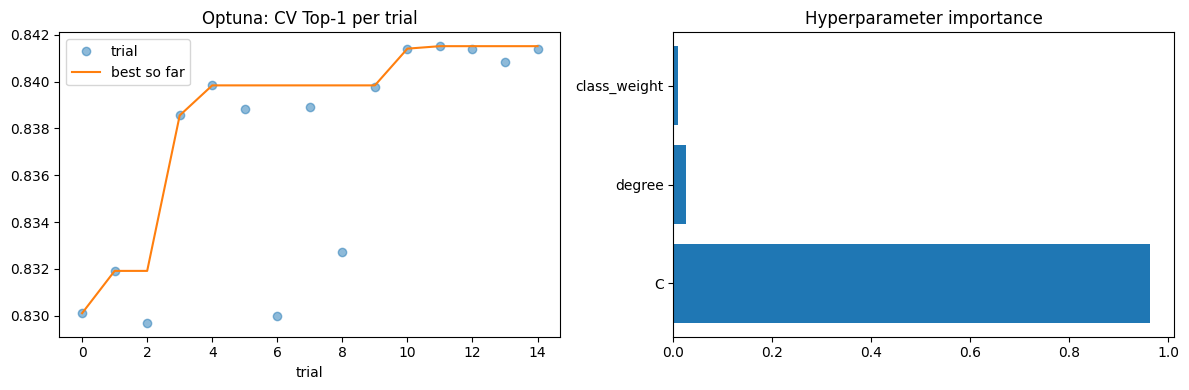

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(trials["number"], trials["value"], "o", alpha=0.5, label="trial")
ax[0].plot(trials["number"], trials["value"].cummax(), "-", label="best so far")
ax[0].set_title("Optuna: CV Top-1 per trial"); ax[0].set_xlabel("trial"); ax[0].legend()
try:
    imp = optuna.importance.get_param_importances(study)
    ax[1].barh(list(imp.keys()), list(imp.values())); ax[1].set_title("Hyperparameter importance")
except Exception as e:
    ax[1].text(0.1, 0.5, f"importance unavailable: {e}")
plt.tight_layout(); plt.savefig("optuna_logreg.png", dpi=150); plt.show()

## 8. Refit Tuned Model & Final Comparison (student-test)

In [19]:
bp = study.best_params
make_tuned = lambda: build_pipe(bp["C"], bp["class_weight"], bp["degree"])
tuned_name = "LR tuned (Bayesian)"
tuned_cfg = f"C={bp['C']:.4f}, class_weight={bp['class_weight']}, poly degree={bp['degree']}"

cvm, cvs = group_cv(make_tuned, FEATURES)
tuned = make_tuned()
t0 = time.time(); tuned.fit(train_df[FEATURES], train_df["label"]); fit_t = time.time() - t0
te, p = evaluate(tuned, test_df, FEATURES)
tr_, _ = evaluate(tuned, train_df, FEATURES)
models[tuned_name] = (tuned, FEATURES); probs[tuned_name] = p

results = pd.concat([results, pd.DataFrame([{
    "Model": tuned_name, "Config": tuned_cfg,
    "CV Top-1": cvm["top1"], "CV Top-1 std": cvs["top1"],
    "CV Macro F1": cvm["macro_f1"], "CV Log Loss": cvm["logloss"],
    "Train Top-1": tr_["Top-1 (all points)"], "Fit Time (s)": fit_t,
    **{f"Test {k}": v for k, v in te.items()}}])], ignore_index=True)

results.to_csv("model_comparison_logreg.csv", index=False)
display(results.set_index("Model").T.round(4))
print(f"Bayesian tuning cost: {tune_time:.0f} s for {N_TRIALS} trials")

Model,"LR baseline (2 features, as before)",LR improved (untuned),LR tuned (Bayesian)
Config,"dist_m + heading_diff_deg, C=1, max_iter=1000","10 features, scaled, C=1, no poly","C=0.0018, class_weight=None, poly degree=1"
CV Top-1,0.772219,0.838626,0.841515
CV Top-1 std,0.097644,0.098061,0.099441
CV Macro F1,0.787515,0.79851,0.797256
CV Log Loss,0.469257,0.434753,0.436391
Train Top-1,0.777076,0.843652,0.845724
Fit Time (s),3.802881,11.366574,6.103808
Test Accuracy,0.795506,0.803356,0.801425
Test Precision,0.740397,0.766917,0.760467
Test Recall,0.72777,0.708023,0.712182


Bayesian tuning cost: 530 s for 15 trials


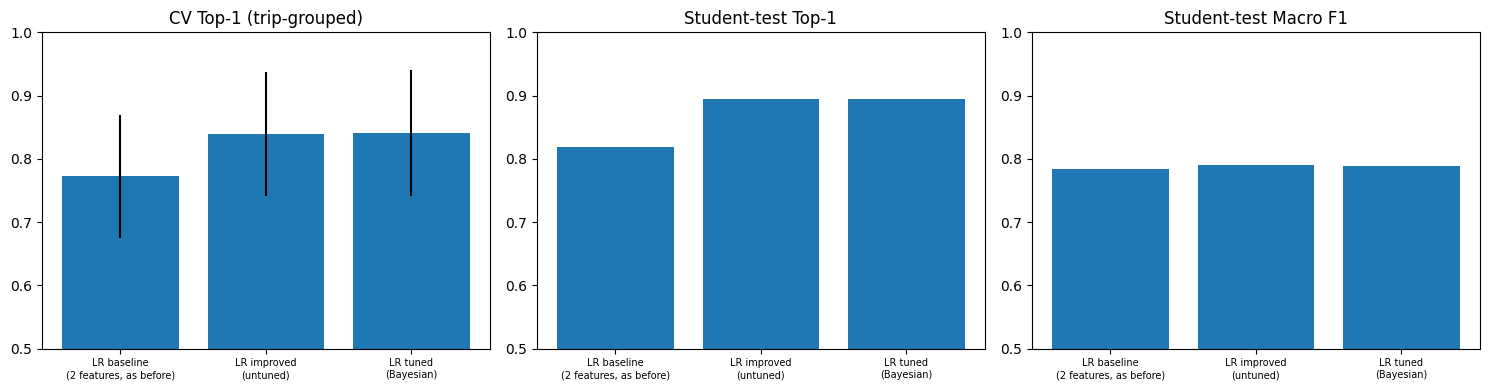

Confusion matrix (student-test, tuned):
 [[100645  16665]
 [ 21382  52908]]
              precision    recall  f1-score   support

           0       0.82      0.86      0.84    117310
           1       0.76      0.71      0.74     74290

    accuracy                           0.80    191600
   macro avg       0.79      0.79      0.79    191600
weighted avg       0.80      0.80      0.80    191600



,points,top1,miss_rate
trip,,,
00000000,2503,0.9545,0.0040
00000007,1354,0.9032,0.0000
00000009,1049,0.9047,0.0029
00000040,2995,0.9376,0.0007
00000052,262,0.9809,0.0000
00000056,3958,0.9242,0.0005
00000065,768,0.9115,0.0260
00000076,1486,0.9428,0.0040
00000077,3911,0.7663,0.0010


In [20]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
names = results["Model"].str.replace(" (", "\n(", regex=False)
ax[0].bar(names, results["CV Top-1"], yerr=results["CV Top-1 std"]); ax[0].set_title("CV Top-1 (trip-grouped)")
ax[1].bar(names, results["Test Top-1 (all points)"]); ax[1].set_title("Student-test Top-1")
ax[2].bar(names, results["Test Macro F1"]); ax[2].set_title("Student-test Macro F1")
for a in ax: a.tick_params(axis="x", labelsize=7); a.set_ylim(0.5, 1.0)
plt.tight_layout(); plt.savefig("logreg_comparison.png", dpi=150); plt.show()

# confusion matrix + per-trip Top-1 for the tuned model (diagnostics)
pred = (probs[tuned_name] >= 0.5).astype(int)
print("Confusion matrix (student-test, tuned):\n", confusion_matrix(test_df["label"], pred))
print(classification_report(test_df["label"], pred))

per_trip = []
for tid, g in test_df.assign(prob=probs[tuned_name]).groupby("trip_id"):
    o = pf.observation_metrics(g["trip_id"].values, g["point_idx"].values, g["prob"].values, g["label"].values)
    per_trip.append({"trip": tid, "points": o["n_points"], "top1": o["top1_all"], "miss_rate": o["miss_rate"]})
display(pd.DataFrame(per_trip).set_index("trip").round(4))

## 9. Save Artifacts for the API

In [21]:
artifact = {
    "model": tuned,
    "features": FEATURES,
    "best_params": bp,
    "candidate_config": {"K_FINAL": pf.K_FINAL, "K_PRE": pf.K_PRE,
                         "HEAD_WIN": pf.HEAD_WIN, "NBR_OFFSETS": list(pf.NBR_OFFSETS)},
    "threshold": 0.5,
    "seed": SEED,
}
joblib.dump(artifact, "pathsnap_logreg_tuned.pkl")
print("Saved pathsnap_logreg_tuned.pkl, pathsnap_features.py, CSVs and plots.")

from google.colab import files
for f in ["pathsnap_logreg_tuned.pkl", "pathsnap_features.py", "model_comparison_logreg.csv",
          "bayesian_trials_logreg.csv", "bayesian_best_logreg.json",
          "data_quality_train.csv", "data_quality_student_test.csv",
          "optuna_logreg.png", "logreg_comparison.png"]:
    files.download(f)

Saved pathsnap_logreg_tuned.pkl, pathsnap_features.py, CSVs and plots.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (9 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Notes
- **Top-1 (all points)** counts a point as wrong when the reference arc is not in the candidate set; **Top-1 (ref arc in candidates)** excludes those points. The candidate miss rate caps the first number.
- Logistic regression scores each candidate **independently**. Route continuity and the remaining errors are handled by the HMM/Viterbi stage, which uses these probabilities as emissions (`candidate_arc_id` and `point_idx` are kept for that).
- **Do not** re-tune or change features after looking at the evaluator-testing trips.
- In the API: `pipe = joblib.load("pathsnap_logreg_tuned.pkl")`, build features with `pf.build_trip_features(track, nodes, arcs, route=None)` (no route file), then `pipe["model"].predict_proba(feats[pipe["features"]])[:, 1]`.

In [22]:
from sklearn.base import clone
import folium

# everything below reuses variables created in Part 1 (train_df, test_df, tuned, FEATURES, pf, paths)
TRAIN_ALL = train_raw          # all training points (no gaps) for decoder tuning
PART_DIRS = {"train": train_dir, "student_test": test_dir}

In [23]:
%%writefile pathsnap_hmm.py
"""PathSnap HMM / Viterbi route reconstruction (shared by the notebook and the API).

Hidden state  : at GPS point i, the state is WHICH of the K candidate road arcs the vehicle is on.
Emission      : w_emit * log(P(candidate is correct)) from the classifier (floored for stability).
Transition    : based on road-network connectivity between candidate arcs of consecutive points.
Decoding      : Viterbi over the time-varying candidate lattice (log-space).
"""
import difflib
import numpy as np
import pandas as pd

DEFAULT_PARAMS = dict(
    w_emit=1.0,        # scale of the classifier log-probability
    lam_hop=1.0,       # cost per road hop when moving forward along connected arcs
    lam_back=2.5,      # cost for a small backwards step (GPS noise jitter)
    pen_disc=6.0,      # cost for a disconnected jump (finite, so decoding never breaks)
    max_hops=4,        # forward hops searched between consecutive GPS points
    gap_soft_s=3.0,    # every this many seconds of gap widens the hop search by 1
    gap_reset_s=30.0,  # gaps this long (or longer) -> no transition constraint (restart)
    p_floor=1e-4,      # floor for classifier probabilities before taking log
)


class RoadGraph:
    """Directed arc graph: arc a -> arc b if arcs[a].to_node == arcs[b].from_node."""

    def __init__(self, arcs):
        self.from_n = arcs["from_node_id"].values.astype(np.int64)
        self.to_n = arcs["to_node_id"].values.astype(np.int64)
        n_nodes = int(max(self.from_n.max(), self.to_n.max())) + 1
        order = np.argsort(self.from_n, kind="stable")
        self.out_arcs = order
        self.out_ptr = np.searchsorted(self.from_n[order], np.arange(n_nodes + 1))
        self._cache = {}

    def successors(self, a):
        n = self.to_n[a]
        return self.out_arcs[self.out_ptr[n]:self.out_ptr[n + 1]]

    def reach(self, a, max_hops):
        """{arc: hops} reachable from arc a within max_hops (a itself = 0 hops)."""
        key = (a, max_hops)
        if key in self._cache:
            return self._cache[key]
        dist = {a: 0}
        frontier = [a]
        for h in range(1, max_hops + 1):
            nxt = []
            for x in frontier:
                for s in self.successors(x):
                    s = int(s)
                    if s not in dist:
                        dist[s] = h
                        nxt.append(s)
            frontier = nxt
            if not frontier:
                break
        self._cache[key] = dist
        return dist

    def transition(self, prev, nxt, dt, p):
        """Log-transition matrix (len(prev) x len(nxt)). Never -inf: invalid transitions get a finite penalty."""
        if dt >= p["gap_reset_s"]:                       # long GPS gap: restart, no constraint
            return np.zeros((len(prev), len(nxt)))
        extra = int(max(dt - 1.0, 0.0) // p["gap_soft_s"])   # shorter gaps: search further, penalise less
        H = min(int(p["max_hops"]) + extra, 10)
        pen = p["pen_disc"] / (1 + extra)

        T = np.full((len(prev), len(nxt)), -pen)
        nidx = {int(b): j for j, b in enumerate(nxt)}
        pidx = {int(a): i for i, a in enumerate(prev)}

        for i, a in enumerate(prev):                      # forward moves (same arc = 0 hops)
            for b, h in self.reach(int(a), H).items():
                j = nidx.get(b)
                if j is not None:
                    T[i, j] = -min(p["lam_hop"] * h, pen)
        back = -min(p["lam_back"], pen)                   # small backwards step: a is a successor of b
        for j, b in enumerate(nxt):
            for a, h in self.reach(int(b), 1).items():
                if h == 1:
                    i = pidx.get(a)
                    if i is not None and T[i, j] < back:
                        T[i, j] = back
        return T


def decode_trip(feats, graph, timestamps, params=None):
    """feats: candidate table of ONE trip with columns point_idx, dist_rank, orig_idx,
    candidate_arc_id, prob.  timestamps: cleaned-track timestamps indexed by point_idx.
    Returns one row per GPS point with the classifier-only arc and the HMM/Viterbi arc."""
    p = {**DEFAULT_PARAMS, **(params or {})}
    f = feats.sort_values(["point_idx", "dist_rank"], kind="stable")
    if len(f) == 0:
        return pd.DataFrame(columns=["point_idx", "orig_idx", "clf_arc", "hmm_arc"])

    uniq, start = np.unique(f["point_idx"].values, return_index=True)
    cands = np.split(f["candidate_arc_id"].values.astype(np.int64), start[1:])
    probs = np.split(f["prob"].values.astype(float), start[1:])
    orig = f["orig_idx"].values[start]
    ts = np.asarray(timestamps, dtype=float)[uniq]
    n = len(uniq)

    emit = [p["w_emit"] * np.log(np.clip(pr, p["p_floor"], 1.0)) for pr in probs]
    clf = np.array([c[int(np.argmax(pr))] for c, pr in zip(cands, probs)])

    delta, back = emit[0], []
    for i in range(1, n):
        T = graph.transition(cands[i - 1], cands[i], ts[i] - ts[i - 1], p)
        sc = delta[:, None] + T
        bp = sc.argmax(axis=0)
        delta = sc[bp, np.arange(len(cands[i]))] + emit[i]
        back.append(bp)

    k = int(np.argmax(delta))
    path = [k]
    for bp in reversed(back):
        k = int(bp[k])
        path.append(k)
    path.reverse()
    hmm = np.array([cands[i][path[i]] for i in range(n)])
    return pd.DataFrame({"point_idx": uniq, "orig_idx": orig, "clf_arc": clf, "hmm_arc": hmm})


# ---------------------------------------------------------------- metrics
def dedup(seq):
    out = []
    for x in seq:
        if not out or out[-1] != x:
            out.append(x)
    return out


def route_metrics(pred_arcs, ref_route, graph, with_seq=False):
    """Pointwise accuracy, route-set P/R/F1, route continuity and (optionally) sequence similarity."""
    pred = np.asarray(pred_arcs)
    ref_list = dedup([int(x) for x in ref_route])
    ref_set = set(ref_list)
    d = dedup([int(x) for x in pred])
    ps = set(d)
    inter = len(ps & ref_set)
    prec = inter / max(len(ps), 1)
    rec = inter / max(len(ref_set), 1)
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0

    pairs = len(d) - 1
    jumps = sum(1 for a, b in zip(d[:-1], d[1:]) if graph.to_n[a] != graph.from_n[b])
    out = {
        "point_acc": float(np.isin(pred, list(ref_set)).mean()),
        "route_prec": prec, "route_rec": rec, "route_f1": f1,
        "continuity": 1.0 - jumps / pairs if pairs > 0 else 1.0,
        "n_jumps": jumps,
        "n_segments": len(d),
    }
    if with_seq:
        out["seq_sim"] = difflib.SequenceMatcher(None, d, ref_list, autojunk=False).ratio()
    return out


# ---------------------------------------------------------------- one-call API helper
def reconstruct_trip(pf, artifact, hmm_params, track, nodes, arcs, trip_id="trip"):
    """Full inference for ONE trip (no route / ground truth needed):
    features -> classifier probabilities -> Viterbi. Returns the per-point DataFrame."""
    feats = pf.build_trip_features(track, nodes, arcs, route=None, trip_id=trip_id)
    feats["prob"] = artifact["model"].predict_proba(feats[artifact["features"]])[:, 1]
    clean, _ = pf.clean_track(track)
    return decode_trip(feats, RoadGraph(arcs), clean["timestamp"].values.astype(float), hmm_params)

Writing pathsnap_hmm.py


In [24]:
import importlib
import pathsnap_hmm as hm
importlib.reload(hm)
print("Default decoder params:", hm.DEFAULT_PARAMS)

Default decoder params: {'w_emit': 1.0, 'lam_hop': 1.0, 'lam_back': 2.5, 'pen_disc': 6.0, 'max_hops': 4, 'gap_soft_s': 3.0, 'gap_reset_s': 30.0, 'p_floor': 0.0001}


In [25]:
TRIPS = {}   # cache: graph, timestamps and reference route per trip

def get_trip(partition, tid):
    key = (partition, tid)
    if key not in TRIPS:
        d = pf.load_trip(PART_DIRS[partition], tid)
        clean, _ = pf.clean_track(d["track"])
        TRIPS[key] = {"graph": hm.RoadGraph(d["arcs"]),
                      "ts": clean["timestamp"].values.astype(float),
                      "ref": d["route"]["arc_id"].astype(int).values}
    return TRIPS[key]

def run_decoding(partition, df, params, with_seq=False, keep=False):
    rows, outs = [], {}
    for tid, g in df.groupby("trip_id"):
        T = get_trip(partition, tid)
        t0 = time.time()
        out = hm.decode_trip(g, T["graph"], T["ts"], params)
        dec_t = time.time() - t0
        mc = hm.route_metrics(out["clf_arc"].values, T["ref"], T["graph"], with_seq)
        mh = hm.route_metrics(out["hmm_arc"].values, T["ref"], T["graph"], with_seq)
        rows.append({"trip": tid, "points": len(out), "decode_s": dec_t,
                     **{f"clf_{k}": v for k, v in mc.items()},
                     **{f"hmm_{k}": v for k, v in mh.items()}})
        if keep:
            outs[tid] = out
    res = pd.DataFrame(rows).set_index("trip")
    return (res, outs) if keep else res

def summarize(res, tag):
    w = res["points"]
    s = {"Pointwise Acc (pooled)": (res[f"{tag}_point_acc"] * w).sum() / w.sum(),
         "Pointwise Acc (trip mean)": res[f"{tag}_point_acc"].mean(),
         "Route F1": res[f"{tag}_route_f1"].mean(),
         "Route Continuity": res[f"{tag}_continuity"].mean(),
         "Disconnected Jumps (total)": int(res[f"{tag}_n_jumps"].sum())}
    if f"{tag}_seq_sim" in res:
        s["Sequence Similarity"] = res[f"{tag}_seq_sim"].mean()
    return s

In [26]:
rng = np.random.RandomState(SEED)
all_train_trips = sorted(TRAIN_ALL["trip_id"].unique())
TUNE_TRIPS = sorted(rng.choice(all_train_trips, size=16, replace=False).tolist())

fit_rows = train_df[~train_df["trip_id"].isin(TUNE_TRIPS)]
oof_model = clone(tuned).fit(fit_rows[FEATURES], fit_rows["label"])

tune_df = TRAIN_ALL[TRAIN_ALL["trip_id"].isin(TUNE_TRIPS)].copy()
tune_df["prob"] = oof_model.predict_proba(tune_df[FEATURES])[:, 1]
print("decoder-tuning trips:", len(TUNE_TRIPS), "| points:", len(tune_df) // pf.K_FINAL)

res0 = run_decoding("train", tune_df, hm.DEFAULT_PARAMS)
print("Default decoder params on tuning trips:")
display(pd.DataFrame({"Classifier-only": summarize(res0, "clf"), "HMM (default)": summarize(res0, "hmm")}).round(4))

decoder-tuning trips: 16 | points: 39460
Default decoder params on tuning trips:


,Classifier-only,HMM (default)
Pointwise Acc (pooled),0.8488,0.8888
Pointwise Acc (trip mean),0.8731,0.9070
Route F1,0.8463,0.8776
Route Continuity,0.6401,0.8925
Disconnected Jumps (total),5248.0000,662.0000


trial  0 | acc=0.9041 | 6s
trial  1 | acc=0.8824 | 13s
trial  2 | acc=0.9178 | 17s
trial  3 | acc=0.8942 | 23s
trial  4 | acc=0.8810 | 27s
trial  5 | acc=0.8796 | 33s
trial  6 | acc=0.8775 | 40s
trial  7 | acc=0.8799 | 46s
trial  8 | acc=0.8874 | 50s
trial  9 | acc=0.8851 | 54s
trial 10 | acc=0.9047 | 59s
trial 11 | acc=0.9034 | 64s
trial 12 | acc=0.9205 | 69s
trial 13 | acc=0.9062 | 76s
trial 14 | acc=0.9113 | 79s
trial 15 | acc=0.9208 | 85s
trial 16 | acc=0.9057 | 92s
trial 17 | acc=0.9069 | 97s
trial 18 | acc=0.9030 | 104s
trial 19 | acc=0.9057 | 109s
trial 20 | acc=0.8977 | 115s
trial 21 | acc=0.9224 | 120s
trial 22 | acc=0.9013 | 125s
trial 23 | acc=0.9203 | 132s
trial 24 | acc=0.9198 | 137s

Best pooled accuracy: 0.9224
Best params: {'w_emit': 0.3489845571155802, 'lam_hop': 2.773973398117207, 'lam_back': 4.148735357365903, 'pen_disc': 10.77645904203327, 'max_hops': 4} | trials: 25 | time (s): 137


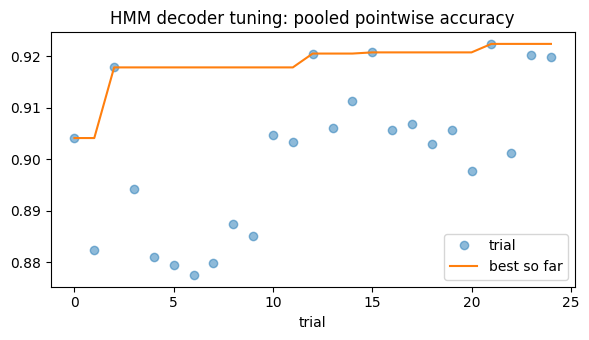

In [27]:
N_TRIALS = 25

def objective(trial):
    params = dict(
        w_emit=trial.suggest_float("w_emit", 0.3, 3.0, log=True),
        lam_hop=trial.suggest_float("lam_hop", 0.1, 3.0),
        lam_back=trial.suggest_float("lam_back", 0.5, 6.0),
        pen_disc=trial.suggest_float("pen_disc", 2.0, 20.0),
        max_hops=trial.suggest_int("max_hops", 2, 6),
    )
    r = run_decoding("train", tune_df, {**hm.DEFAULT_PARAMS, **params})
    trial.set_user_attr("continuity", float(r["hmm_continuity"].mean()))
    return float(summarize(r, "hmm")["Pointwise Acc (pooled)"])

def log_trial(study, trial):
    print(f"trial {trial.number:2d} | acc={trial.value:.4f} | {time.time()-t0:.0f}s")

t0 = time.time()
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=N_TRIALS, timeout=900, callbacks=[log_trial])
tune_time = time.time() - t0

BEST = {**hm.DEFAULT_PARAMS, **study.best_params}
print("\nBest pooled accuracy:", round(study.best_value, 4))
print("Best params:", study.best_params, "| trials:", len(study.trials), "| time (s):", round(tune_time))

trials = study.trials_dataframe()
trials.to_csv("bayesian_trials_hmm.csv", index=False)
json.dump({"params": BEST, "best_value": study.best_value, "n_trials": len(study.trials),
           "tuning_time_s": tune_time, "tune_trips": TUNE_TRIPS, "seed": SEED},
          open("hmm_config.json", "w"), indent=2)

plt.figure(figsize=(6, 3.5))
plt.plot(trials["number"], trials["value"], "o", alpha=0.5, label="trial")
plt.plot(trials["number"], trials["value"].cummax(), "-", label="best so far")
plt.title("HMM decoder tuning: pooled pointwise accuracy"); plt.xlabel("trial"); plt.legend()
plt.tight_layout(); plt.savefig("optuna_hmm.png", dpi=150); plt.show()

In [28]:
test_df = test_df.copy()
test_df["prob"] = tuned.predict_proba(test_df[FEATURES])[:, 1]

res_def = run_decoding("student_test", test_df, hm.DEFAULT_PARAMS, with_seq=True)
res_tun, outs = run_decoding("student_test", test_df, BEST, with_seq=True, keep=True)

summary = pd.DataFrame({
    "Classifier-only": summarize(res_tun, "clf"),
    "Classifier + HMM (default params)": summarize(res_def, "hmm"),
    "Classifier + HMM (tuned params)": summarize(res_tun, "hmm"),
}).round(4)
display(summary)
summary.to_csv("hmm_comparison_student_test.csv")
print(f"Mean Viterbi decode time per trip: {res_tun['decode_s'].mean():.2f} s | max: {res_tun['decode_s'].max():.2f} s")

,Classifier-only,Classifier + HMM (default params),Classifier + HMM (tuned params)
Pointwise Acc (pooled),0.8950,0.9355,0.9668
Pointwise Acc (trip mean),0.9102,0.9441,0.9619
Route F1,0.8701,0.8986,0.7567
Route Continuity,0.6154,0.9073,0.8258
Disconnected Jumps (total),2568.0000,315.0000,399.0000
Sequence Similarity,0.6491,0.8653,0.7536


Mean Viterbi decode time per trip: 0.23 s | max: 0.48 s


,points,clf_acc,hmm_acc,acc_change,clf_continuity,hmm_continuity,clf_jumps,hmm_jumps,clf_seq_sim,hmm_seq_sim
trip,,,,,,,,,,
00000000,2503,0.9545,0.9840,0.0296,0.4989,0.8741,223,18,0.5504,0.8669
00000007,1354,0.9032,1.0000,0.0968,0.6320,0.8116,124,13,0.5249,0.7254
00000009,1049,0.9047,0.9085,0.0038,0.6821,0.7479,144,60,0.8018,0.6527
00000040,2995,0.9376,0.9930,0.0554,0.5887,0.8982,290,23,0.5852,0.8358
00000052,262,0.9809,0.9504,-0.0305,0.7531,0.8269,20,9,0.8588,0.6892
00000056,3958,0.9242,0.9298,0.0056,0.6511,0.7601,531,160,0.7744,0.5655
00000065,768,0.9115,0.9258,0.0143,0.6372,0.8100,82,19,0.6935,0.7724
00000076,1486,0.9428,0.9818,0.0390,0.6674,0.7963,149,55,0.7995,0.8124
00000077,3911,0.7663,0.9811,0.2148,0.5029,0.9267,859,17,0.2604,0.9142


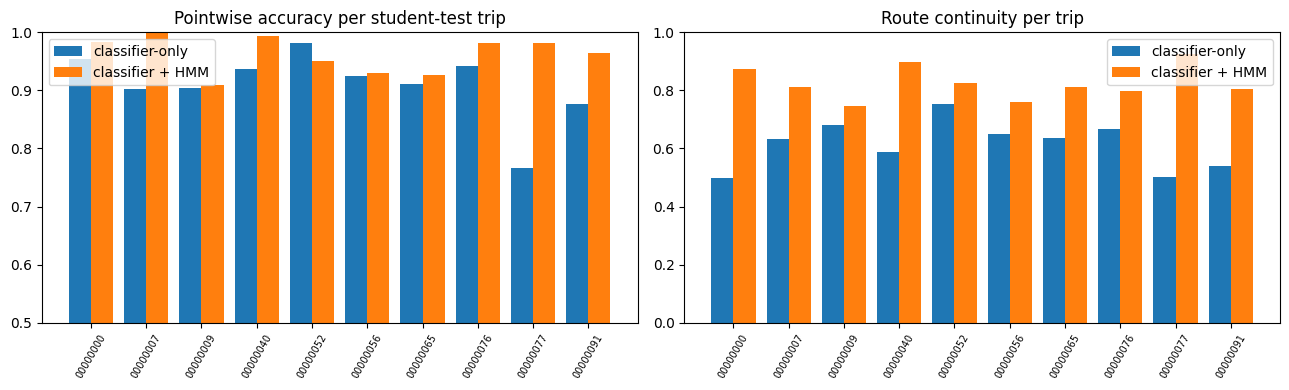

Trips where HMM did not improve pointwise accuracy: ['00000052']


In [29]:
cmp = pd.DataFrame({
    "points": res_tun["points"],
    "clf_acc": res_tun["clf_point_acc"], "hmm_acc": res_tun["hmm_point_acc"],
    "acc_change": res_tun["hmm_point_acc"] - res_tun["clf_point_acc"],
    "clf_continuity": res_tun["clf_continuity"], "hmm_continuity": res_tun["hmm_continuity"],
    "clf_jumps": res_tun["clf_n_jumps"], "hmm_jumps": res_tun["hmm_n_jumps"],
    "clf_seq_sim": res_tun["clf_seq_sim"], "hmm_seq_sim": res_tun["hmm_seq_sim"],
}).round(4)
display(cmp)
cmp.to_csv("hmm_per_trip_student_test.csv")

x = np.arange(len(cmp)); w = 0.4
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(x - w/2, cmp["clf_acc"], w, label="classifier-only"); ax[0].bar(x + w/2, cmp["hmm_acc"], w, label="classifier + HMM")
ax[0].set_xticks(x); ax[0].set_xticklabels(cmp.index, rotation=60, fontsize=7); ax[0].set_ylim(0.5, 1.0)
ax[0].set_title("Pointwise accuracy per student-test trip"); ax[0].legend()
ax[1].bar(x - w/2, cmp["clf_continuity"], w, label="classifier-only"); ax[1].bar(x + w/2, cmp["hmm_continuity"], w, label="classifier + HMM")
ax[1].set_xticks(x); ax[1].set_xticklabels(cmp.index, rotation=60, fontsize=7); ax[1].set_ylim(0, 1.0)
ax[1].set_title("Route continuity per trip"); ax[1].legend()
plt.tight_layout(); plt.savefig("hmm_vs_classifier.png", dpi=150); plt.show()

not_helped = cmp[cmp["acc_change"] <= 0]
print("Trips where HMM did not improve pointwise accuracy:", list(not_helped.index) if len(not_helped) else "none")

In [30]:
import folium

MAP_TRIP = list(outs.keys())[0]
d = pf.load_trip(test_dir, MAP_TRIP)
nodes, arcs, track, route = d["nodes"], d["arcs"], pf.clean_track(d["track"])[0], d["route"]
out = outs[MAP_TRIP]

def arc_lines(arc_ids):
    lines = []
    for a in hm.dedup([int(x) for x in arc_ids]):
        f, t = arcs.iloc[a]["from_node_id"], arcs.iloc[a]["to_node_id"]
        lines.append([[nodes.iloc[f]["lat"], nodes.iloc[f]["lon"]], [nodes.iloc[t]["lat"], nodes.iloc[t]["lon"]]])
    return lines

m = folium.Map(location=[track["lat"].mean(), track["lon"].mean()], zoom_start=15, tiles="OpenStreetMap")

g_gps = folium.FeatureGroup(name="GPS observations (blue)")
for _, r in track.iloc[::2].iterrows():
    folium.CircleMarker([r["lat"], r["lon"]], radius=2, color="blue", fill=True, fill_opacity=0.6).add_to(g_gps)
g_ref = folium.FeatureGroup(name="Reference route (green)")
for ln in arc_lines(route["arc_id"].values): folium.PolyLine(ln, color="green", weight=7, opacity=0.5).add_to(g_ref)
g_clf = folium.FeatureGroup(name="Classifier-only (orange)", show=False)
for ln in arc_lines(out["clf_arc"].values): folium.PolyLine(ln, color="orange", weight=4, opacity=0.9).add_to(g_clf)
g_hmm = folium.FeatureGroup(name="Classifier + HMM (red)")
for ln in arc_lines(out["hmm_arc"].values): folium.PolyLine(ln, color="red", weight=3, opacity=0.95).add_to(g_hmm)
for g in [g_gps, g_ref, g_clf, g_hmm]: g.add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
m.get_root().html.add_child(folium.Element(
    '<div style="position:fixed;bottom:30px;left:30px;z-index:9999;background:white;padding:8px;border:1px solid #888;font-size:12px">'
    f'<b>Trip {MAP_TRIP}</b><br><span style="color:blue">&#9679;</span> GPS<br><span style="color:green">&#9632;</span> Reference route<br>'
    '<span style="color:orange">&#9632;</span> Classifier-only<br><span style="color:red">&#9632;</span> Classifier + HMM</div>'))
m.save(f"map_trip_{MAP_TRIP}.html")
m

In [31]:
print("Saved: hmm_config.json, pathsnap_hmm.py, bayesian_trials_hmm.csv, hmm_comparison_student_test.csv, hmm_per_trip_student_test.csv, plots and map.")
from google.colab import files
for f in ["pathsnap_hmm.py", "hmm_config.json", "bayesian_trials_hmm.csv",
          "hmm_comparison_student_test.csv", "hmm_per_trip_student_test.csv",
          "optuna_hmm.png", "hmm_vs_classifier.png", f"map_trip_{MAP_TRIP}.html"]:
    files.download(f)

Saved: hmm_config.json, pathsnap_hmm.py, bayesian_trials_hmm.csv, hmm_comparison_student_test.csv, hmm_per_trip_student_test.csv, plots and map.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (7 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Notes for the report and the API
- **Pointwise accuracy** = share of GPS points whose chosen arc is in the reference route. **Route continuity** = share of consecutive distinct predicted arcs that are connected on the network. **Sequence similarity** = difflib ratio between the decoded arc sequence (consecutive duplicates removed) and the reference route.
- Discuss the trips listed under "did not improve": typical causes are candidate misses, parallel roads, and reference routes that are not fully connected.
- API usage (Laptop 1), per request, with no ground truth involved:
```python
import joblib, json, pathsnap_features as pf, pathsnap_hmm as hm
artifact = joblib.load("pathsnap_logreg_tuned.pkl")
hmm_params = json.load(open("hmm_config.json"))["params"]
out = hm.reconstruct_trip(pf, artifact, hmm_params, track, nodes, arcs, trip_id)   # columns: point_idx, orig_idx, clf_arc, hmm_arc
```
- Ground-truth `.route` is read only in the scoring module, never in `reconstruct_trip`.